# KQC SampleHolderTest — 40 RF launchers joined pairwise by 20 CPWs (Quantcore PDK rebuild)

**What the chip is.** **Source:** KQCircuits `chips/sample_holder_test.py` (`SampleHolderTest`, default parameters, chip name "CTest"),
© IQM Finland Oy, GPL-3.0 (`other-libs/KQCircuits-main/.../kqcircuits/chips/sample_holder_test.py`,
<https://github.com/iqm-finland/KQCircuits>). Spec: `docs/designs/kqc/test_chips.md` (row *SampleHolderTest*).

A sample-holder test: 40 RF launchers (pad width 160 µm, gap 96 µm, 520 µm from the chip edge, pitch 635 µm), ten
per side, and 20 CPWs that join them in pairs. PL-1 … PL-10 run from the north pads (left → right) to the east pads
(bottom → top), PL-11 … PL-20 from the south pads (right → left) to the west pads (top → bottom); each goes 1200 µm
straight in from both launcher corners and diagonally between, so the 20 lines are nested.

**Kept exactly (same KQC cells, parameters and positions):** KQC's `produce_n_launchers(40, "RF", 160, 96,
520, 635)`: 40 `Launcher(s = l = a_launcher = 160, b_launcher = launcher_frame_gap = 96)` cells at KQC's positions
(port ids clockwise from the top-left pad, as KQC numbers them) with KQC's names; the 20 lines as Designer routes
with KQC's nodes (launcher port → corner ± 1200 µm → other corner ± 1200 µm → port). Results 1 XORs the chip with a stand-alone KQC build.

**Substituted:** the launchers are 40 `Launcher` instances (`PL<i>_IN.port` / `PL<i>_OUT.port`) instead of chip
launchers (`launchers=`): the Designer's chip launchers know the sample holders SMA8, ARD24 and DC24 only (open request). The cells, parameters and positions are KQC's, so the layout is the same; the LOM sees
the same 50 Ω ports.

**This rebuild on the Quantcore PDK** (not a replica; we distribute it under GPL-3.0):

| topic | KQC source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 10 × 10 mm, KQC `ChipFrame` | same 10 × 10 mm, Quantcore die frame (L dicing markers, 3 × 3 alignment grids, chip boundary, device ID "CTest") |
| launchers | 40 RF launchers (`produce_n_launchers`), outer etch 104 µm from the edge | the same 40 `Launcher` cells with `edge="auto"`: outer etch `frame.pad_edge` = 100 µm from the edge (4 µm further out) |
| substrate | silicon (KQC simulation default) | sapphire 650 µm, εr 10.25 |
| junctions | none | none |
| cheese | KQC's whole-area ground grid (`with_grid`, in KQC's mask builds) | **the original wins:** KQC's grid (`with_grid=True`), so no PDK band |
| elements, positions, routes | — | kept: KQC's cells, parameters, positions and paths; waypoints from the launcher ports |
| placement | centred | centred (checked in Design 5, no shift) |

**How this notebook goes.** First the **Design**: the chip is laid out one segment at a time, each segment its
own cell with a picture of the chip so far — the empty die, the 40 RF launchers and the pad rule, the test structures (none besides the lines), the routing (the 20 nested lines), and then the whole chip (the centring and the save). Then the same steps as the Flow strip of the Quantcore
KLayout plugin: **Check** (DRC, netlist) → **LOM** (simulation and plots) → **Simulate** (export to HFSS, the
component simulation, the eigenmode simulation, the full-wave run) → **Results** (plots, the values, FEM against the
LOM, a feedback step and the iteration to a target) → **Fab**.

**Nothing here solves on its own.** The switches (the code cell after Setup) are off (`RUN_FEM = False`): FEM results
are loaded when a solve has been kept, otherwise each FEM cell says what would appear. The notebook before this
rewrite (the layout in a few cells, with its outputs) is kept as `sample_holder_test.v1.ipynb`; both save the same `sample_holder_test.json`.

This test chip has no circuit to simulate (through lines only): the LOM and Simulate steps say in one sentence why
not, and the Results step is the comparison with KQC's own build (the XOR); Check and Fab run as in the v1.

## Setup

The imports, the output folders and the switches. `FULL_FAB = False` skips the fab-only corner rounding in
Fab 1 (`qcc mask` writes the complete file). The segment pictures go to `build/snapshots/sample_holder_test/` (not kept
in the repo), the final snapshots next to the notebook.

`LIVE`: with KLayout open (the default) every change below is pushed to the KLayout window as you run it; with
`QCC_LIVE=0` the notebook builds headless and only writes files. `_common` holds the helpers the design
notebooks share (tables, snapshots, the PDK placement, the FEM and feedback steps).

**The switches** (next cell): `RUN_FEM` solves the FEM jobs in AEDT 2024 R1 or newer, one after the other (a new
non-graphical AEDT unless `AEDT_MODE` says otherwise; an AEDT you have open is never touched); `RESOLVE` solves again
even when kept results match; `FEM_FAST` exports with the library's fast test settings (minutes, values not
converged); `MAX_ITER` caps the feedback iterations towards the targets.

On this chip the FEM switches change nothing (it has no sim groups); they are kept so that every design notebook
starts the same way.

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
from kqcircuits.pya_resolver import pya

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/kqc/test_chips")                 # design JSON + final snapshots
STEPS = Path("build/snapshots/sample_holder_test")  # step-by-step snapshots (build/ is not kept in the repo)

In [3]:
RUN_FEM = False        # True (or a set such as {"q3d_cmatrix"}): solve the FEM jobs in AEDT 2024 R1+, one at a time
RESOLVE = False        # True (or a set of analyses): solve again even when kept results match
FEM_FAST = True        # True: the library's fast test settings (minutes, not converged); False: the settings as written
AEDT_MODE = "batch"    # "batch" (no window) | "gui" (a new AEDT window, left open) | "attach" (the AEDT you have open)
MAX_ITER = 3           # feedback iterations towards the targets (Results 5)

## The Quantcore PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack, the frame and pad rule, the cheese / 3/0 rules and the fab layer map.

In [4]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

# Design: the layout, one segment at a time

The chip is built the way it is laid out by hand: the die, the launchers, the lines between them, and then the
whole chip. A sample-holder test has no qubits, readout or coupling, and its lines are the only test structure, so
segment 3 is one sentence. Each segment is one cell with one picture of the chip so far; the order is the v1's.
KQC's ground grid (`with_grid`, ≈ 0.8 M holes) is drawn in every build, so each picture rebuilds the whole chip:
the pictures stay at the v1's size, one per segment.

| segment | what is placed here |
|---|---|
| 1 | the 10 × 10 mm die with the Quantcore frame (no chip launchers: the 40 are cells, Design 2) |
| 2 | bond pads: KQC's 40 RF launchers, ten per side, slid to the PDK pad edge (`edge="auto"`) |
| 3 | test structures: none besides the lines (the lines are the test) |
| 4 | the routing: 20 nested CPWs joining the launchers in pairs (north → east, south → west) |
| 5 | the whole chip: the centring check and the save |

## Design 1 · The die and its frame

`Designer(...)` starts the 10 × 10 mm chip with the chip name "CTest" (the device ID); the 40 launchers are cells placed in Design 2. `with_grid=True`
asks for KQC's whole-area ground grid (the original's cheese): the PDK band is then not added. The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0); KQC's own `ChipFrame` is not drawn.

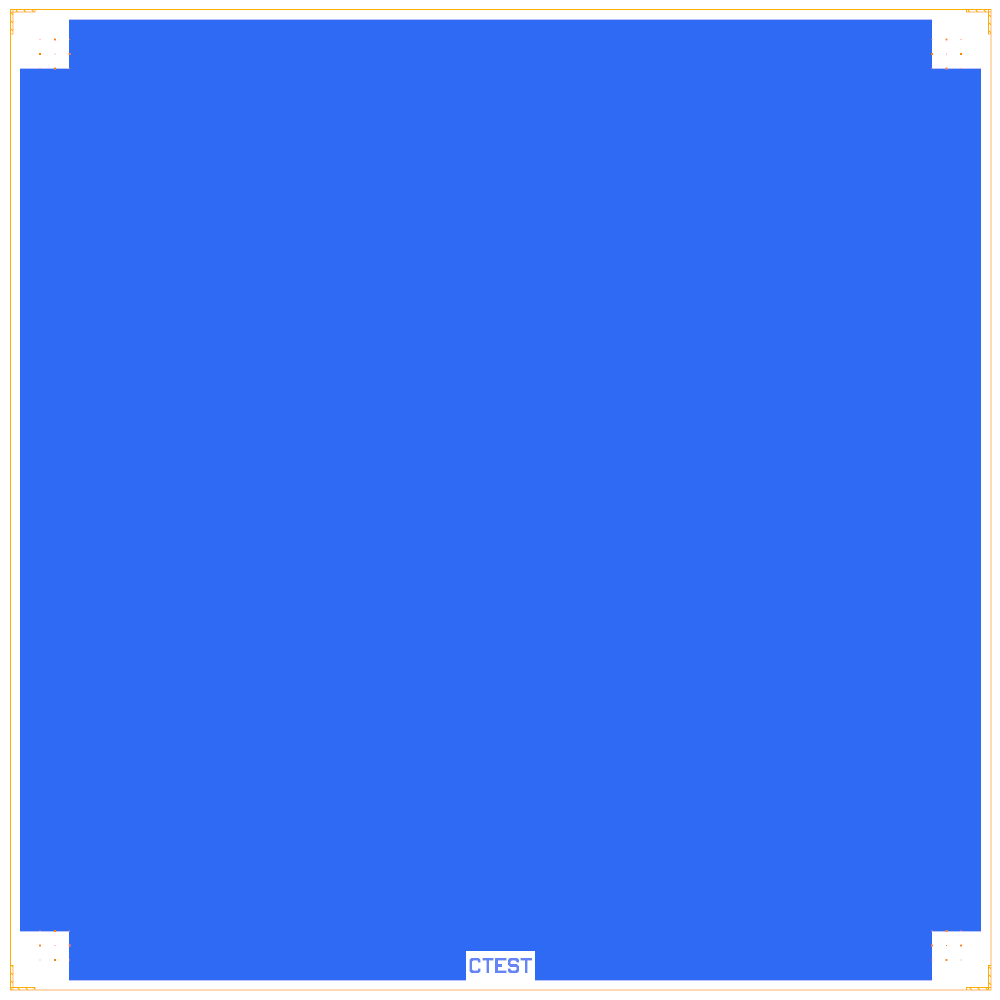

**On the chip so far:** 0 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** nothing new to the layout.

WindowsPath('build/snapshots/sample_holder_test/1_die.png')

In [5]:
d = Designer("sample_holder_test", box=(0, 0, 10000, 10000), chip={"name_chip": "CTest", "with_grid": True},
             live=LIVE)
CHIP = dict(box=(-100, -100, 10100, 10100), size=(1000, 1000), width=420)   # the v1's full-chip picture
layout_step(d, STEPS / "1_die.png", **CHIP)

## Design 2 · Bond pads: the 40 launchers and the pad rule

KQC's `produce_n_launchers(40, "RF", 160, 96, 520, 635)`: ten RF launchers per side on a 635 µm pitch, as 40
`Launcher` cells (pad and taper 160 µm, gap 96 µm) with KQC's names and port ids (clockwise from the top-left pad).
KQC puts their ports 520 µm in, so the outer etch edge ends 520 − 160 − 160 − 96 = 104 µm from the die edge.
**PDK rule:** the outer etch edge sits `frame.pad_edge` (100 µm) from the die edge; `edge="auto"` in `d.add` slides
each launcher perpendicular to its edge until it does (4 µm out). The table measures the result. (The Designer's
chip launchers know the SMA8, ARD24 and DC24 holders only, so the 40 are placed as cells.)

The picture zooms on the north-east corner (the last north pads, the first east pads).

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PL1_IN | `Launcher` | n | 100.0 | ✓ |
| PL2_IN | `Launcher` | n | 100.0 | ✓ |
| PL3_IN | `Launcher` | n | 100.0 | ✓ |
| PL4_IN | `Launcher` | n | 100.0 | ✓ |
| PL5_IN | `Launcher` | n | 100.0 | ✓ |
| PL6_IN | `Launcher` | n | 100.0 | ✓ |
| PL7_IN | `Launcher` | n | 100.0 | ✓ |
| PL8_IN | `Launcher` | n | 100.0 | ✓ |
| PL9_IN | `Launcher` | n | 100.0 | ✓ |
| PL10_IN | `Launcher` | n | 100.0 | ✓ |
| PL10_OUT | `Launcher` | e | 100.0 | ✓ |
| PL9_OUT | `Launcher` | e | 100.0 | ✓ |
| PL8_OUT | `Launcher` | e | 100.0 | ✓ |
| PL7_OUT | `Launcher` | e | 100.0 | ✓ |
| PL6_OUT | `Launcher` | e | 100.0 | ✓ |
| PL5_OUT | `Launcher` | e | 100.0 | ✓ |
| PL4_OUT | `Launcher` | e | 100.0 | ✓ |
| PL3_OUT | `Launcher` | e | 100.0 | ✓ |
| PL2_OUT | `Launcher` | e | 100.0 | ✓ |
| PL1_OUT | `Launcher` | e | 100.0 | ✓ |
| PL11_OUT | `Launcher` | s | 100.0 | ✓ |
| PL12_OUT | `Launcher` | s | 100.0 | ✓ |
| PL13_OUT | `Launcher` | s | 100.0 | ✓ |
| PL14_OUT | `Launcher` | s | 100.0 | ✓ |
| PL15_OUT | `Launcher` | s | 100.0 | ✓ |
| PL16_OUT | `Launcher` | s | 100.0 | ✓ |
| PL17_OUT | `Launcher` | s | 100.0 | ✓ |
| PL18_OUT | `Launcher` | s | 100.0 | ✓ |
| PL19_OUT | `Launcher` | s | 100.0 | ✓ |
| PL20_OUT | `Launcher` | s | 100.0 | ✓ |
| PL20_IN | `Launcher` | w | 100.0 | ✓ |
| PL19_IN | `Launcher` | w | 100.0 | ✓ |
| PL18_IN | `Launcher` | w | 100.0 | ✓ |
| PL17_IN | `Launcher` | w | 100.0 | ✓ |
| PL16_IN | `Launcher` | w | 100.0 | ✓ |
| PL15_IN | `Launcher` | w | 100.0 | ✓ |
| PL14_IN | `Launcher` | w | 100.0 | ✓ |
| PL13_IN | `Launcher` | w | 100.0 | ✓ |
| PL12_IN | `Launcher` | w | 100.0 | ✓ |
| PL11_IN | `Launcher` | w | 100.0 | ✓ |

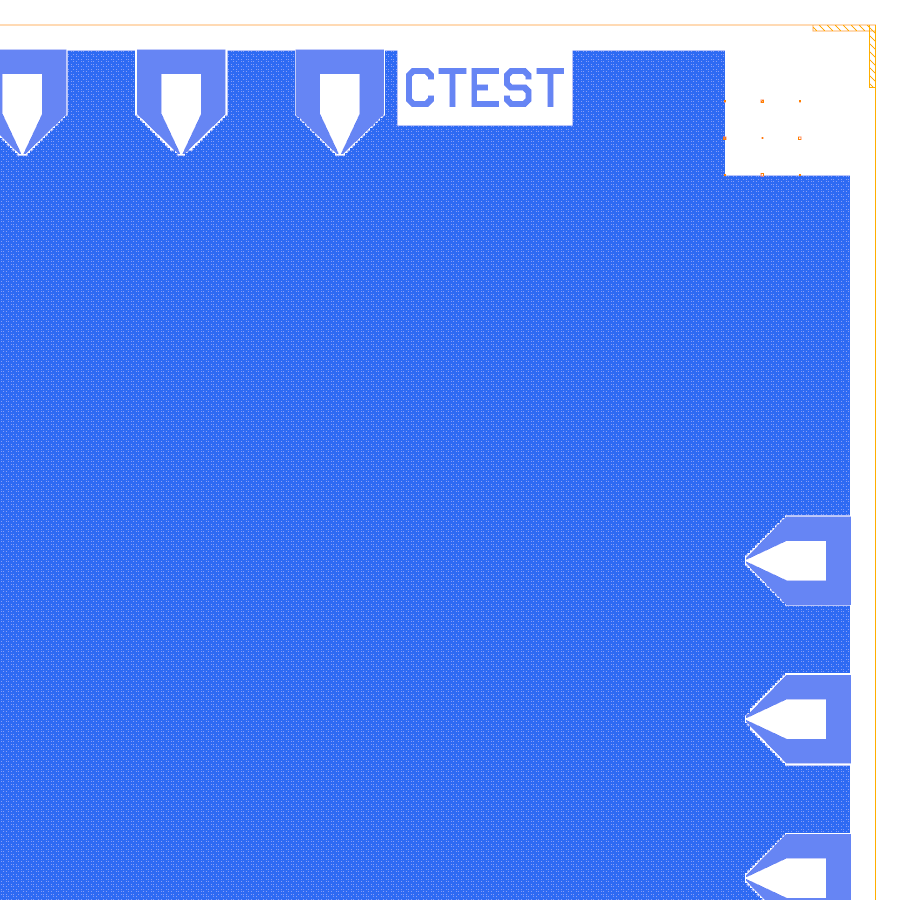

**On the chip so far:** 40 pads · 0 qubits · 0 other components · 0 routes · 0 declared couplings. **This step added** 40 component(s) `PL1_IN`, `PL2_IN`, `PL3_IN`, `PL4_IN`, `PL5_IN`, `PL6_IN`, `PL7_IN`, `PL8_IN` … (+32).

WindowsPath('build/snapshots/sample_holder_test/2_launchers.png')

In [6]:
n, pitch, width, gap, indent, side, r = 40, 635, 160, 96, 520, 10000, 100   # KQC defaults; chip 10 mm, turn radius
per = n // 4
launcher = dict(s=width, l=width, a_launcher=width, b_launcher=gap, launcher_frame_gap=gap)
# KQC produce_n_launchers: per side a chip-box transform; u runs along the side, pads face inward
sides = [(lambda u: (u, side - indent), 90),             # north, left → right (port ids 1 … 10)
         (lambda u: (side - indent, side - u), 0),       # east, top → bottom (11 … 20)
         (lambda u: (side - u, indent), 270),            # south, right → left (21 … 30)
         (lambda u: (indent, u), 180)]                   # west, bottom → top (31 … 40)
name_of = {}                                             # KQC launcher_assignments
for i in range(1, per + 1):
    name_of[i] = f"PL{i}_IN"
    name_of[2 * per + 1 - i] = f"PL{i}_OUT"
    name_of[2 * per + i] = f"PL{per + i}_OUT"
    name_of[4 * per + 1 - i] = f"PL{per + i}_IN"
with d.batch():
    pid = 0
    for pos, rot in sides:
        for i in range(per):
            pid += 1
            d.add(name_of[pid], "Launcher", at=pos(side / 2 + pitch * (i + 0.5 - per / 2)), rot=rot, edge="auto",
                  **launcher)
rebuild(d)                                       # a live=False Designer builds on request: the table reads this build
display(Markdown(pads_md(d)))
layout_step(d, STEPS / "2_launchers.png", box=(6500, 6500, 10100, 10100), size=(900, 900), width=360)

## Design 3 · Test structures: none besides the lines

The 40 launchers are the only components (Design 2), and what the chip tests is the 20 lines between them (the
sample holder's connections, end to end), so there is nothing to place here.

## Design 4 · Routing: the 20 nested lines

The 20 lines join the launchers in pairs: PL-1 … PL-10 from the north pads (left → right) to the east pads
(bottom → top), PL-11 … PL-20 from the south pads (right → left) to the west pads (top → bottom). Each goes 1200 µm
straight in from both launcher corners and diagonally between, so the 20 lines are nested (KQC's
`_produce_waveguide(i, ∓1200, …)`). `corner(ref, shift)` is KQC's `"<port>_corner"` refpoint (one turn radius in)
plus a shift; the ports are read after the pad rule moved the launchers, so the lines follow them.

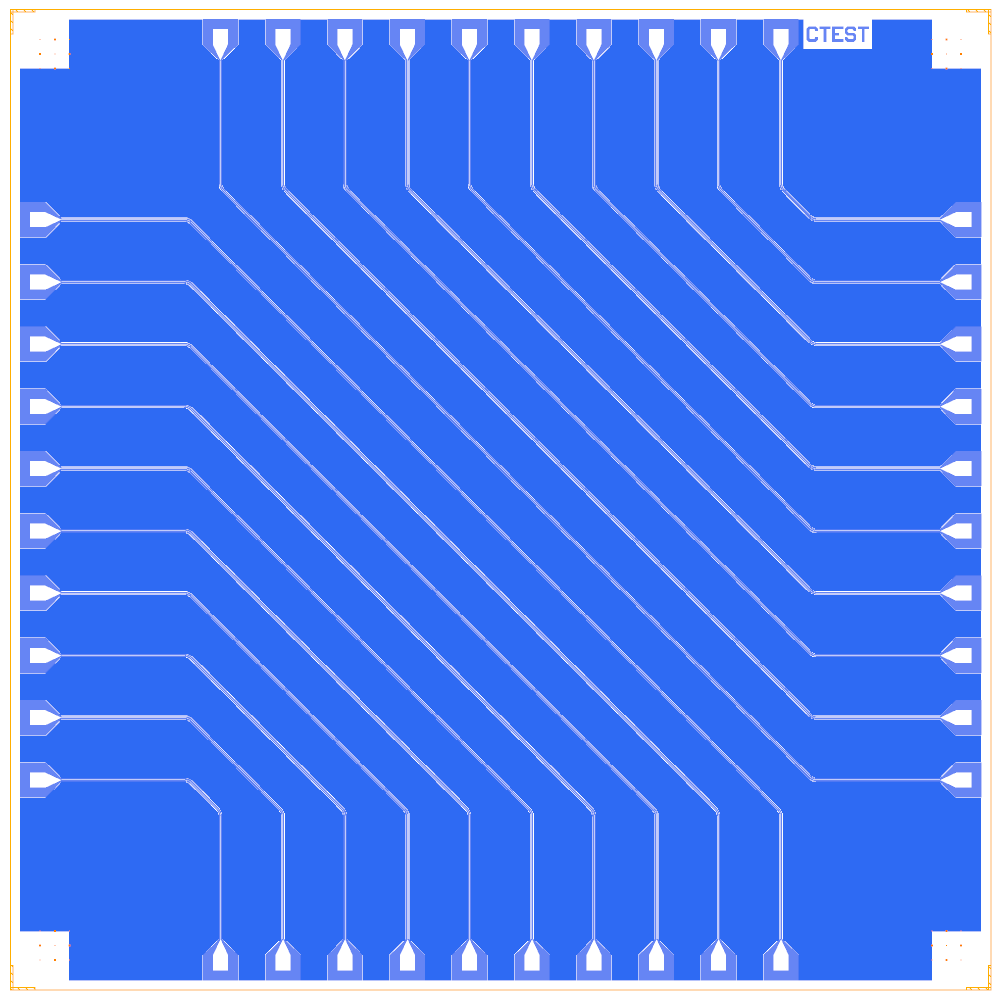

**On the chip so far:** 40 pads · 0 qubits · 0 other components · 20 routes · 0 declared couplings. **This step added** 20 route(s) `PL1`, `PL2`, `PL3`, `PL4`, `PL5`, `PL6`, `PL7`, `PL8` … (+12).

{'PL1': 11135.37, 'PL2': 10237.34, 'PL3': 9339.31, 'PL4': 8441.29, 'PL5': 7543.26, 'PL6': 6645.24, 'PL7': 5747.21, 'PL8': 4849.19, 'PL9': 3951.16, 'PL10': 3053.13, 'PL11': 11135.37, 'PL12': 10237.34, 'PL13': 9339.31, 'PL14': 8441.29, 'PL15': 7543.26, 'PL16': 6645.24, 'PL17': 5747.21, 'PL18': 4849.19, 'PL19': 3951.16, 'PL20': 3053.13}


In [7]:
def corner(ref, shift):                                  # KQC "<port>_corner" (one r inward) + a shift
    x, y, ang = port_info(d, ref)
    return (x + r * math.cos(math.radians(ang)) + shift[0], y + r * math.sin(math.radians(ang)) + shift[1])


with d.batch():
    for i in range(1, 2 * per + 1):                      # KQC _produce_waveguide(i, ∓1200, first, second)
        first, second, dist = ("IN", "OUT", -1200) if i <= per else ("OUT", "IN", 1200)
        a_ref, b_ref = f"PL{i}_{first}.port", f"PL{i}_{second}.port"
        d.route(f"PL{i}", a_ref, b_ref, nodes=[corner(a_ref, (0, dist)), corner(b_ref, (dist, 0))])
layout_step(d, STEPS / "4_routes.png", **CHIP)
print({k: round(v, 2) for k, v in d.result.route_lengths().items()})

## Design 5 · The whole chip: centring, save

No sim groups: through lines only (the v1 rebuild has none; Simulate says what one would take). `center_in_die` checks that the content sits centred in the die and shifts it if it is more
than 50 µm off. Then the design is saved with `save_design`, which compares it with the file it replaces (the
previous run's): the order is the v1's, so it should say *same design*.

In [8]:
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN, same = save_design(d, OUT / "sample_holder_test.json")
display(Markdown(same))
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)


**Same design as before:** `examples/designs/kqc/test_chips/sample_holder_test.json` is identical to the file it replaces (byte for byte). The segments changed how the chip is built, not the chip.

<Designer sample_holder_test: 40 instances, 20 routes, live=False> → examples\designs\kqc\test_chips\sample_holder_test.json


# Check: DRC and netlist

The plugin's *Check* step: the design rules, then the lumped circuit the layout turns into.

## Check 1 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Expected here (from the v1 run):** DRC clean: no errors, no warnings (the 20 nested lines do not cross and every launcher port is joined) and no PDK design warning; the 40 `pad_edge` warnings of KQC's positions (outer etch 104 µm) are gone. `pdk_report` gives KQC's grid ("the original design's own"), the content centred (0, 0) and no junctions.

In [ ]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

## Check 2 · Netlist

`d.lom()` turns the layout into a lumped circuit from the components' LOM models: launchers are 50 Ω ports, a route
between two ports is one conductor (a through line), a route to a shorted end is a λ/4 resonator.

In [ ]:
lb = d.lom()
print(lom_summary(lb))
print(netlist_md(lb).split('| branch |')[0])

# LOM: nothing to simulate

None: no junctions or resonators (20 × 50 Ω through lines; the lengths are printed in Design 4).

> **Simulation PC (32 GB+ RAM).** The cells below solve FEM jobs in AEDT. On this notebook's chip they need the
> simulation PC: set `RUN_FEM = True` and `FEM_FAST = False` there, run them one job at a time, and keep the results
> (`fem/`). On a smaller PC leave `RUN_FEM = False`: the cells export the jobs and load kept results only.

# Simulate: nothing to export

The design has no sim groups, so the export below writes no FEM job and the switches at the top change nothing here.
What the chip measures, each line's transmission through the sample holder, is a driven S-parameter problem: `sim_tools` exports `hfss_driven` jobs, but for a sim group, and adding
one would change the design file (a new revision of the chip, not this rebuild).

In [ ]:
jobs = export_sims(DESIGN)                       # one job per sim group: this design has none
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

# Results: the layout against the source

The chip has no simulated quantity to hold against a model, so its *compare* step is the XOR with KQC's own build of
the same chip.

## Results 1 · XOR with KQC

**Reference: XOR with the source.** KQC's chip built stand-alone, XOR-ed layer by layer with this build (the union
of both layer sets; `refpoints`, `ports` and the `instance_names` label layer are annotation and are skipped). The
reference gets `name_brand="QC"`; with KQC's default "IQM" the frame text adds its area (last line). The column
"> 1 nm" is the XOR shrunk by one database unit. **The rebuild is expected to differ** by design: the frame (KQC's
ChipFrame vs the Quantcore die frame), the ground grid (KQC's stand-alone build has none) and the launchers moved 4 µm out with their lines' first legs. A reference, not a pass/fail check.

In [ ]:
import klayout.db as kdb
from kqcircuits.chips.sample_holder_test import SampleHolderTest as KqcChip


def xor_vs_kqc(**ref_params):
    ref = pya.Layout()
    ref_top = ref.create_cell("ref")
    ref_top.insert(pya.DCellInstArray(KqcChip.create(ref, **ref_params).cell_index(), pya.DTrans()))
    ly = kdb.Layout()
    ly.read(str(d.out))
    top = ly.top_cell()
    mine = {ly.get_info(i).name: i for i in ly.layer_indexes()}
    theirs = {ref.get_info(i).name: i for i in ref.layer_indexes()}
    rows = []
    for name in sorted(set(mine) | set(theirs)):
        if not name or name in ("refpoints", "instance_names", "ports"):
            continue
        a = kdb.Region(ref_top.begin_shapes_rec(theirs[name])).merged() if name in theirs else kdb.Region()
        b = kdb.Region(top.begin_shapes_rec(mine[name])).merged() if name in mine else kdb.Region()
        if a.is_empty() and b.is_empty():
            continue
        x = a ^ b
        rows.append((name, x.area() * ref.dbu ** 2, x.sized(-1).area() * ref.dbu ** 2,
                     None if x.is_empty() else x.bbox().to_dtype(ref.dbu)))
    return rows


rows = xor_vs_kqc(name_brand="QC")
table = ["| layer | XOR area (µm²) | > 1 nm (µm²) | where |", "|---|---|---|---|"]
table += [f"| {n} | {x:.3g} | {y:.3g} | {w or ''} |" for n, x, y, w in rows]
total, real = sum(r[1] for r in rows), sum(r[2] for r in rows)
iqm = sum(r[1] for r in xor_vs_kqc())
display(Markdown("\n".join(table) + f"\n\n**Total XOR area: {total:.3g} µm²** ({real:.3g} µm² wider than 1 nm). "
                 f"Against KQC's default brand text \"IQM\": {iqm:.3g} µm²."))

**From the v1 run:** the XOR (1.5 × 10⁸ µm²) is all from the expected differences: the qcc frame layers (the boundary layer covers the die, 1 × 10⁸ µm², plus the markers), the ground grid (2.1 × 10⁷ µm²) and its avoidance, KQC's frame (EBL, dicing and airbridge-marker layers), and the launchers' 4 µm shift on the base etch and the waveguide path.

## Results 2 · Feedback: none

There is no target to iterate towards: the lines follow KQC's paths and parameters, and a variant (another pitch, other launcher pairs) is a
new layout, checked again by the DRC and the XOR above.

# Fab: the mask, snapshots, summary

## Fab 1 · Build and export

**The design file.** `sample_holder_test.json` (saved in Design 5) is the whole design: `qcc build
examples/designs/kqc/test_chips/sample_holder_test.json` rebuilds `build/sample_holder_test.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers,
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: KQC's grid drawn in the build (`with_grid=True`) stands, and no PDK band is added. In the v1 run: 1/0 844 830 polygons, 3/0 808 845; cheese source `build`, 844 805 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/kqc/test_chips/sample_holder_test.json` writes the complete file.

In [ ]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

## Fab 2 · Snapshots

The snapshots of the source notebook (full chip and its zooms; the die frame's south-west corner, dicing L on
1000/0 and the 3 × 3 alignment grid on 1001/0) and two east-side launchers in the **fab view** (the mask from Fab 1: 1/0
and 3/0 with the grid holes). KQC's grid fills the ground as one tone at full-chip scale; the chip boundary 100/0
is drawn as an outline.

In [ ]:
show_snapshot(d, OUT / "sample_holder_test.png", box=(-100, -100, 10100, 10100))
show_snapshot(d, OUT / "sample_holder_test_corner.png", box=(6500, 6500, 10000, 10000), width=480)
show_snapshot(d, OUT / "sample_holder_test_frame.png", box=(0, 0, 900, 900), size=(900, 900), width=300)
snap_file(Path("build") / "sample_holder_test_fab.oas", OUT / "sample_holder_test_fab.png", box=(9250, 4650, 10000, 5400), size=(1200, 1200), width=420);

## Summary

| | |
|---|---|
| **matches the source** | KQC's cells with their parameters, positions and paths; KQC's whole-area ground grid |
| **differs (PDK)** | the Quantcore die frame instead of KQC's ChipFrame; the 40 launchers 4 µm further out (outer etch 100 µm, `frame.pad_edge`), the lines' end legs with them; sapphire |
| **PDK design warnings** | as listed in Check 1 |
| **FEM** | no sim groups, no jobs |
| layout | built in five segments (the die, the 40 launchers, no other test structure, the 20 lines, the whole chip); the saved JSON is the v1 notebook's |
| feedback | none: through lines, no simulated quantity; the XOR with KQC is the compare step (Results 1) |
| open | a driven S-parameter job of one line would need a sim group (a new design revision) |